# MonsoonLens AI: Historical Rainfall Pattern Analysis
## Notebook 01: Comprehensive Exploratory Data Analysis (EDA)

**Stage:** Stage 2 — Exploratory Data Analysis & Climatological Diagnostics  
**Dataset:** Historical Area-Weighted Rainfall across 36 Subdivisions of India (1901–2015)  
**Authors:** MonsoonLens AI Team  

---

### Notebook Objectives:
1. **Data Ingestion & Integrity Audit:** Re-verify cleaned wide, long, annual, and seasonal datasets.
2. **Annual Rainfall Trajectories:** Analyze 115-year national and subdivisional precipitation trends and moving averages.
3. **Monthly & Seasonal Climatology:** Characterize calendar month progression and the 4 IMD meteorological seasons.
4. **Regional Disparities & Spatial Variability:** Quantify rainfall variability using the Coefficient of Variation ($CV$).
5. **Distributional Analysis & Correlations:** Inspect positive skewness, extreme observations, and inter-seasonal correlations.
6. **Foundations for Stage 3:** Provide empirical insights to guide subsequent anomaly detection and change-point detection.


In [1]:
import sys
import json
from pathlib import Path

# Add project root to sys.path so src imports work reliably
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import (
    CLEANED_WIDE_PATH,
    MONTHLY_LONG_PATH,
    ANNUAL_PATH,
    SEASONAL_PATH,
    QUALITY_FLAGS_PATH,
    METADATA_PATH,
    FIGURES_DIR,
    MONTH_COLUMNS,
    SEASON_COLUMNS,
    SEASON_DESCRIPTIONS,
)

# Plot configuration for high-resolution graphics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print("Environment configured successfully.")


Environment configured successfully.


## 1. Ingest Verified Processed Datasets

We load the five analysis-ready datasets generated and validated during Stage 1.


In [2]:
df_wide = pd.read_csv(CLEANED_WIDE_PATH)
df_long = pd.read_csv(MONTHLY_LONG_PATH)
df_annual = pd.read_csv(ANNUAL_PATH)
df_seasonal = pd.read_csv(SEASONAL_PATH)
df_flags = pd.read_csv(QUALITY_FLAGS_PATH)

with open(METADATA_PATH, 'r', encoding='utf-8') as f:
    metadata = json.load(f)

print(f"Cleaned Wide Dataset:     {df_wide.shape[0]:,} rows × {df_wide.shape[1]} columns")
print(f"Monthly Long Dataset:     {df_long.shape[0]:,} rows × {df_long.shape[1]} columns")
print(f"Annual Rainfall Dataset:  {df_annual.shape[0]:,} rows × {df_annual.shape[1]} columns")
print(f"Seasonal Rainfall Dataset:{df_seasonal.shape[0]:,} rows × {df_seasonal.shape[1]} columns")
print(f"Quality Flags Catalog:    {df_flags.shape[0]:,} audit records logged")


Cleaned Wide Dataset:     4,116 rows × 26 columns
Monthly Long Dataset:     49,392 rows × 8 columns
Annual Rainfall Dataset:  4,116 rows × 7 columns
Seasonal Rainfall Dataset:16,464 rows × 9 columns
Quality Flags Catalog:    453 audit records logged


## 2. Data Quality & Missingness Audit

In scientific precipitation analysis, missing observations reflect recording gaps (e.g., station network issues) rather than zero precipitation (dry weather). We verify that missing values remain properly preserved as `NaN` without silent zero-imputation.


In [3]:
# Breakdown of missing value flags
missing_flags = df_flags[df_flags['flag_type'].str.contains('MISSING')]
print(f"Total Missing Observation Flags: {len(missing_flags)}")

missing_breakdown = missing_flags.groupby(['subdivision', 'field'])['flag_type'].count().unstack().fillna(0).astype(int)
display(missing_breakdown)


Total Missing Observation Flags: 96


field,ANNUAL,APR,AUG,DEC,FEB,JAN,JUL,JUN,MAR,MAY,NOV,OCT,SEP
subdivision,,,,,,,,,,,,,
ANDAMAN & NICOBAR ISLANDS,6,2,2,3,0,0,2,2,2,1,2,2,3
ARUNACHAL PRADESH,6,0,0,2,1,1,1,1,2,0,2,2,0
COASTAL KARNATAKA,1,0,0,0,0,1,0,0,0,0,0,0,0
JAMMU & KASHMIR,1,0,0,1,0,0,1,0,0,0,1,0,0
LAKSHADWEEP,11,2,2,4,1,2,3,2,2,2,6,3,3
WEST MADHYA PRADESH,1,0,0,0,1,0,0,0,0,0,0,0,0


## 3. Historical All-India Annual Rainfall Trends (1901–2015)

We examine the national aggregate precipitation trajectory across all 36 subdivisions over the 115-year historical record.


115-Year Climatological Mean: 1411.01 mm
Standard Deviation:          115.84 mm
Median Annual:               1414.51 mm
Interquartile Range (IQR):   165.26 mm
Linear Trend Slope:          -0.214 mm/year (p-value: 0.5126, R²: 0.0038)
Wettest Year:                1961 (1717.1 mm)
Driest Year:                 1972 (1146.5 mm)


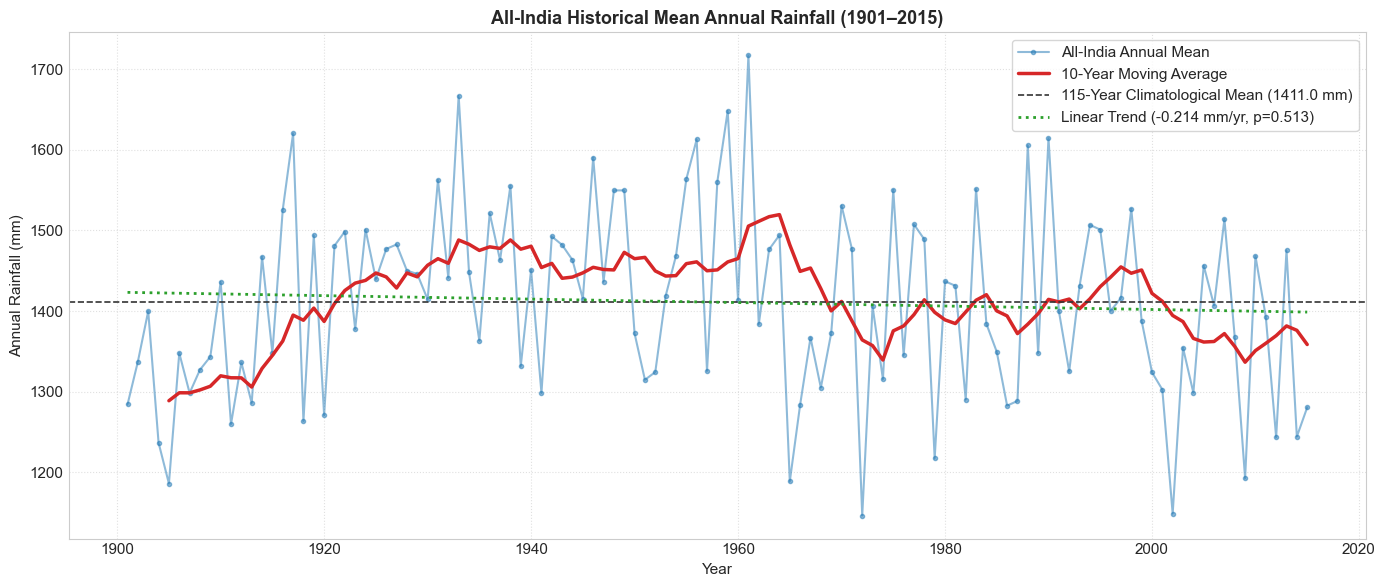

In [4]:
# Compute national annual mean series
national_annual = df_annual.groupby('YEAR')['ANNUAL_VALIDATED'].mean().dropna()

years = national_annual.index.values.astype(float)
rainfall = national_annual.values
reg = stats.linregress(years, rainfall)
moving_avg_10y = national_annual.rolling(window=10, min_periods=5).mean()

print(f"115-Year Climatological Mean: {national_annual.mean():.2f} mm")
print(f"Standard Deviation:          {national_annual.std():.2f} mm")
print(f"Median Annual:               {national_annual.median():.2f} mm")
print(f"Interquartile Range (IQR):   {stats.iqr(national_annual):.2f} mm")
print(f"Linear Trend Slope:          {reg.slope:+.3f} mm/year (p-value: {reg.pvalue:.4f}, R²: {reg.rvalue**2:.4f})")
print(f"Wettest Year:                {int(national_annual.idxmax())} ({national_annual.max():.1f} mm)")
print(f"Driest Year:                 {int(national_annual.idxmin())} ({national_annual.min():.1f} mm)")

# Visualization
plt.figure(figsize=(14, 6))
plt.plot(years, rainfall, color='#1f77b4', alpha=0.5, marker='o', markersize=3, label='All-India Annual Mean')
plt.plot(years, moving_avg_10y, color='#d62728', lw=2.5, label='10-Year Moving Average')
plt.axhline(national_annual.mean(), color='#333333', linestyle='--', lw=1.2, label=f'115-Year Climatological Mean ({national_annual.mean():.1f} mm)')

trendline = reg.intercept + reg.slope * years
plt.plot(years, trendline, color='#2ca02c', linestyle=':', lw=2, label=f'Linear Trend ({reg.slope:+.3f} mm/yr, p={reg.pvalue:.3f})')

plt.title('All-India Historical Mean Annual Rainfall (1901–2015)', fontsize=13, weight='bold')
plt.xlabel('Year', fontsize=11)
plt.ylabel('Annual Rainfall (mm)', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


## 4. Contrasting Subdivisional Annual Trajectories

While the national average exhibits relative stability, individual subdivisions demonstrate vastly different historical baselines and variability.


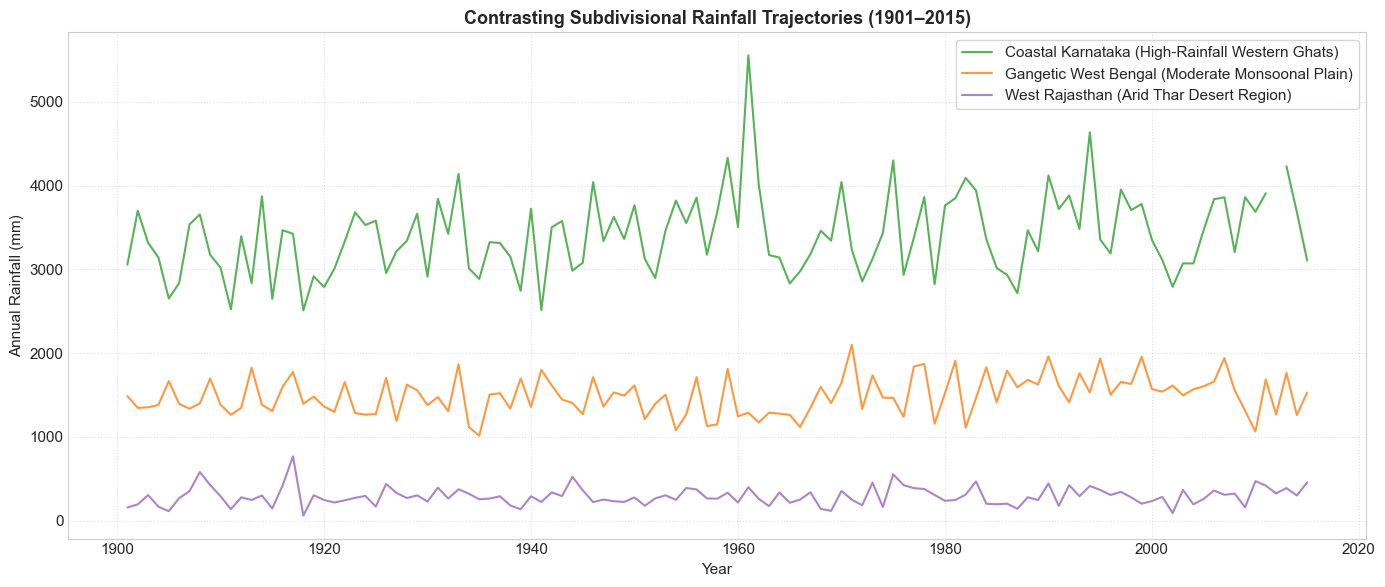

In [5]:
contrast_subs = [
    ('COASTAL KARNATAKA', '#2ca02c', 'Coastal Karnataka (High-Rainfall Western Ghats)'),
    ('GANGETIC WEST BENGAL', '#ff7f0e', 'Gangetic West Bengal (Moderate Monsoonal Plain)'),
    ('WEST RAJASTHAN', '#9467bd', 'West Rajasthan (Arid Thar Desert Region)')
]

plt.figure(figsize=(14, 6))
for sub_name, color, label_str in contrast_subs:
    sub_data = df_annual[df_annual['SUBDIVISION'] == sub_name].sort_values('YEAR')
    plt.plot(sub_data['YEAR'], sub_data['ANNUAL_VALIDATED'], color=color, alpha=0.8, lw=1.5, label=label_str)

plt.title('Contrasting Subdivisional Rainfall Trajectories (1901–2015)', fontsize=13, weight='bold')
plt.xlabel('Year', fontsize=11)
plt.ylabel('Annual Rainfall (mm)', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


## 5. Monthly Rainfall Climatology Profile

We evaluate the calendar month rainfall progression (January to December) to understand seasonal transitions.


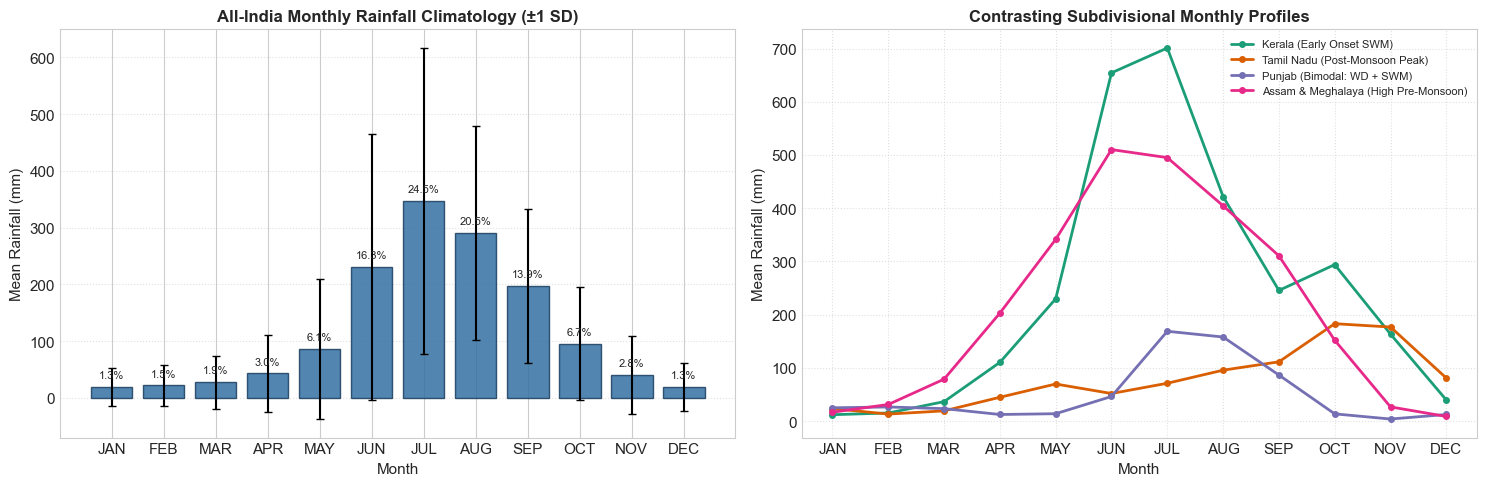

In [6]:
monthly_stats = df_long.groupby(['MONTH_NUMBER', 'MONTH'])['RAINFALL'].agg(
    mean='mean',
    std='std',
    median='median'
).reset_index().sort_values('MONTH_NUMBER')

total_monthly_mean = monthly_stats['mean'].sum()
monthly_stats['share_pct'] = (monthly_stats['mean'] / total_monthly_mean) * 100.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Left: National bar chart with error bars
bars = ax1.bar(monthly_stats['MONTH'], monthly_stats['mean'], yerr=monthly_stats['std'],
               capsize=3, color='#3470a3', edgecolor='#1a3d5e', alpha=0.85)
for bar, pct in zip(bars, monthly_stats['share_pct']):
    ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 12, f"{pct:.1f}%",
             ha='center', va='bottom', fontsize=8)

ax1.set_title('All-India Monthly Rainfall Climatology (±1 SD)', fontsize=12, weight='bold')
ax1.set_xlabel('Month')
ax1.set_ylabel('Mean Rainfall (mm)')
ax1.grid(True, axis='y', linestyle=':', alpha=0.6)

# Right: Selected regional profiles
regional_subs = [
    ('KERALA', '#1b9e77', 'Kerala (Early Onset SWM)'),
    ('TAMIL NADU', '#d95f02', 'Tamil Nadu (Post-Monsoon Peak)'),
    ('PUNJAB', '#7570b3', 'Punjab (Bimodal: WD + SWM)'),
    ('ASSAM & MEGHALAYA', '#e7298a', 'Assam & Meghalaya (High Pre-Monsoon)')
]
for sub_name, color, label_str in regional_subs:
    sub_m = df_long[df_long['SUBDIVISION'] == sub_name].groupby(['MONTH_NUMBER', 'MONTH'])['RAINFALL'].mean().reset_index().sort_values('MONTH_NUMBER')
    ax2.plot(sub_m['MONTH'], sub_m['RAINFALL'], marker='o', lw=2, markersize=4, color=color, label=label_str)

ax2.set_title('Contrasting Subdivisional Monthly Profiles', fontsize=12, weight='bold')
ax2.set_xlabel('Month')
ax2.set_ylabel('Mean Rainfall (mm)')
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


## 6. Seasonal Contributions & Regional Regimes

We analyze the 4 IMD meteorological seasons:
- **Winter:** `Jan-Feb`
- **Pre-Monsoon:** `Mar-May`
- **Southwest Monsoon:** `Jun-Sep`
- **Post-Monsoon:** `Oct-Dec`


,SEASON,SEASON_NAME,mean,std,percent_share
0,Jan-Feb,Winter,40.747786,59.308277,2.878736
1,Mar-May,Pre-Monsoon / Summer,155.901753,201.316965,11.014096
2,Jun-Sep,Southwest Monsoon,1064.724769,707.741531,75.220327
3,Oct-Dec,Post-Monsoon / Northeast Monsoon,154.100487,166.942660,10.886841


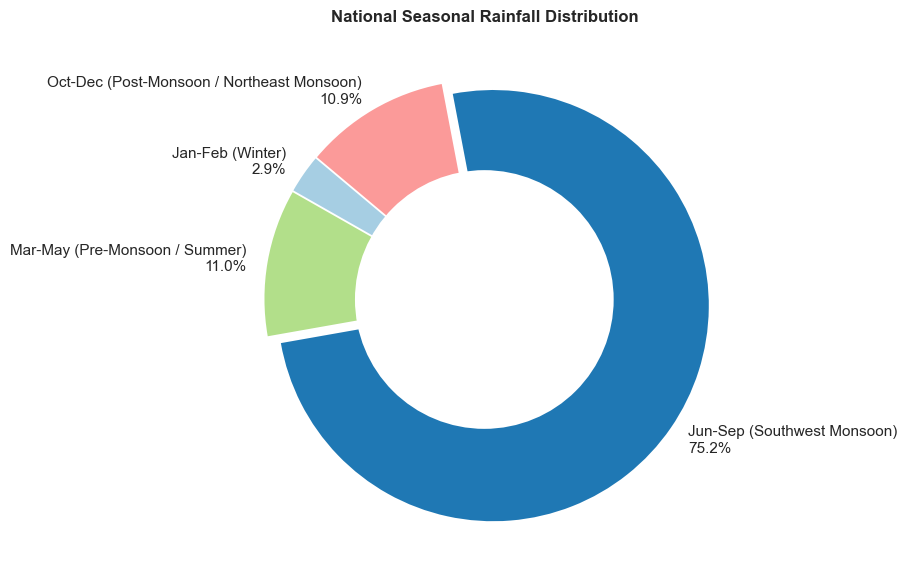

In [7]:
seasonal_summary = df_seasonal.groupby(['SEASON_NUMBER', 'SEASON', 'SEASON_NAME'])['RAINFALL_VALIDATED'].agg(
    mean='mean',
    std='std',
    median='median'
).reset_index().sort_values('SEASON_NUMBER')

total_season_rain = seasonal_summary['mean'].sum()
seasonal_summary['percent_share'] = (seasonal_summary['mean'] / total_season_rain) * 100.0

display(seasonal_summary[['SEASON', 'SEASON_NAME', 'mean', 'std', 'percent_share']])

# Seasonal contribution pie chart
fig, ax = plt.subplots(figsize=(7, 7))
colors = ['#a6cee3', '#b2df8a', '#1f78b4', '#fb9a99']
labels = [f"{row['SEASON']} ({row['SEASON_NAME']})\n{row['percent_share']:.1f}%" for _, row in seasonal_summary.iterrows()]
ax.pie(seasonal_summary['percent_share'], labels=labels, colors=colors, startangle=140, explode=(0.02, 0.02, 0.05, 0.02))
centre_circle = plt.Circle((0,0), 0.60, fc='white')
ax.add_artist(centre_circle)
ax.set_title('National Seasonal Rainfall Distribution', fontsize=12, weight='bold')
plt.show()


## 7. Regional Rainfall Heatmap Across 36 Subdivisions

We map monthly precipitation intensity across all 36 subdivisions, ordered from wettest to driest.


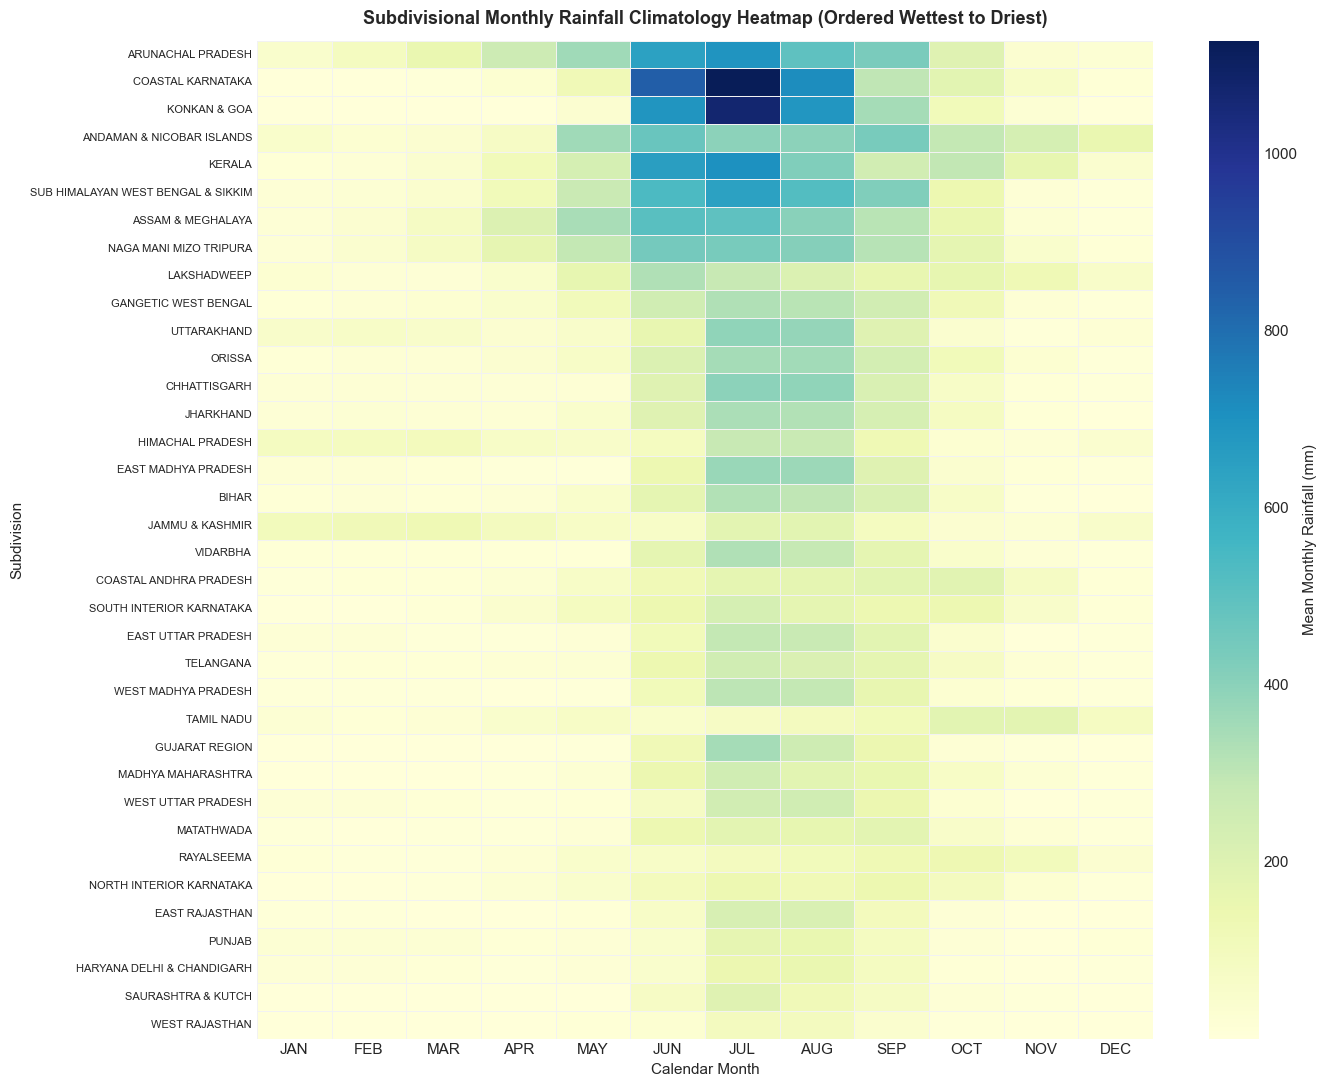

In [8]:
# Compute pivot of monthly means per subdivision
pivot_climatology = df_long.groupby(['SUBDIVISION', 'MONTH_NUMBER'])['RAINFALL'].mean().unstack(level='MONTH_NUMBER')
pivot_climatology.columns = MONTH_COLUMNS

# Order subdivisions by total annual rainfall
sub_annual_means = df_annual.groupby('SUBDIVISION')['ANNUAL_VALIDATED'].mean().sort_values(ascending=False)
pivot_climatology = pivot_climatology.reindex(sub_annual_means.index)

plt.figure(figsize=(14, 11))
sns.heatmap(pivot_climatology, cmap='YlGnBu', cbar_kws={'label': 'Mean Monthly Rainfall (mm)'}, linewidths=0.5, linecolor='#f2f2f2')
plt.title('Subdivisional Monthly Rainfall Climatology Heatmap (Ordered Wettest to Driest)', fontsize=13, weight='bold', pad=12)
plt.xlabel('Calendar Month', fontsize=11)
plt.ylabel('Subdivision', fontsize=11)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()


## 8. Spatial Variability Analysis & Coefficient of Variation ($CV$)

We investigate whether low-rainfall regions experience greater relative variability than high-rainfall regions using the **Coefficient of Variation** ($CV = rac{\sigma}{\mu} 	imes 100\%$).


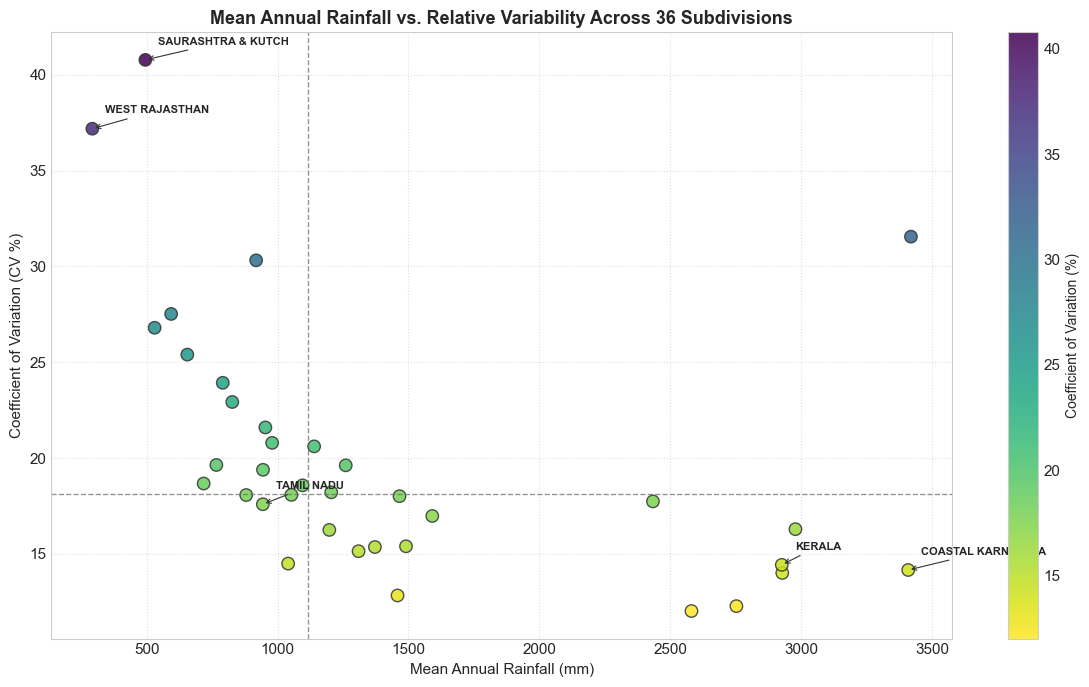

In [9]:
sub_variability = df_annual.groupby('SUBDIVISION')['ANNUAL_VALIDATED'].agg(
    mean='mean',
    std='std'
).reset_index()

sub_variability['cv_percent'] = (sub_variability['std'] / sub_variability['mean']) * 100.0

plt.figure(figsize=(12, 7))
scatter = plt.scatter(sub_variability['mean'], sub_variability['cv_percent'],
                      c=sub_variability['cv_percent'], cmap='viridis_r', s=80, edgecolors='#333333', alpha=0.85)
cbar = plt.colorbar(scatter)
cbar.set_label('Coefficient of Variation (%)', fontsize=10)

plt.axvline(sub_variability['mean'].median(), color='#666666', linestyle='--', lw=1, alpha=0.7)
plt.axhline(sub_variability['cv_percent'].median(), color='#666666', linestyle='--', lw=1, alpha=0.7)

# Key callouts
for _, row in sub_variability.iterrows():
    if row['SUBDIVISION'] in ['WEST RAJASTHAN', 'SAURASHTRA & KUTCH', 'COASTAL KARNATAKA', 'TAMIL NADU', 'KERALA']:
        plt.annotate(row['SUBDIVISION'], xy=(row['mean'], row['cv_percent']),
                     xytext=(row['mean'] + 50, row['cv_percent'] + 0.8),
                     fontsize=8, weight='bold', arrowprops=dict(arrowstyle='->', color='#333333', lw=0.8))

plt.title('Mean Annual Rainfall vs. Relative Variability Across 36 Subdivisions', fontsize=13, weight='bold')
plt.xlabel('Mean Annual Rainfall (mm)', fontsize=11)
plt.ylabel('Coefficient of Variation (CV %)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


## 9. Distributional Analysis & Boxplots

We inspect the dispersion, median, interquartile range, and positive skewness of historical annual rainfall across all subdivisions.


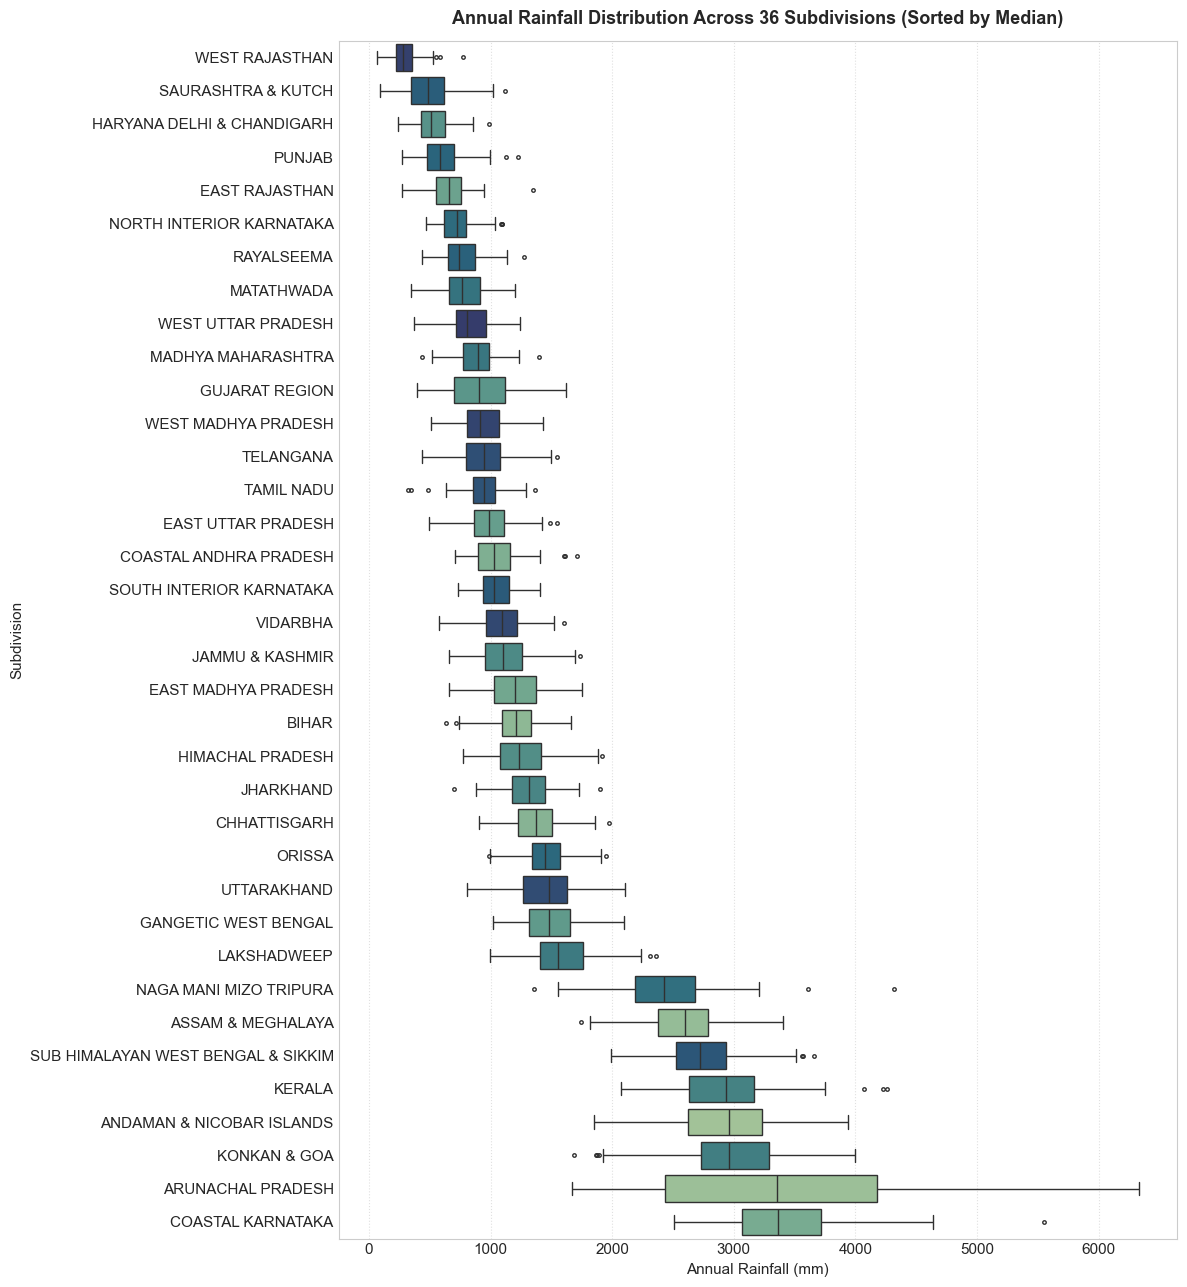

In [10]:
ordered_subs_median = df_annual.groupby('SUBDIVISION')['ANNUAL_VALIDATED'].median().sort_values(ascending=True).index.tolist()

plt.figure(figsize=(12, 13))
sns.boxplot(
    data=df_annual,
    y='SUBDIVISION',
    x='ANNUAL_VALIDATED',
    order=ordered_subs_median,
    hue='SUBDIVISION',
    legend=False,
    palette='crest',
    fliersize=2.5,
    linewidth=1.0
)
plt.title('Annual Rainfall Distribution Across 36 Subdivisions (Sorted by Median)', fontsize=13, weight='bold', pad=12)
plt.xlabel('Annual Rainfall (mm)', fontsize=11)
plt.ylabel('Subdivision', fontsize=11)
plt.grid(True, axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


## 10. Inter-Seasonal Correlation Analysis

We calculate Pearson correlation coefficients between seasons to determine whether pre-monsoon precipitation or winter rainfall can predict southwest monsoon totals.


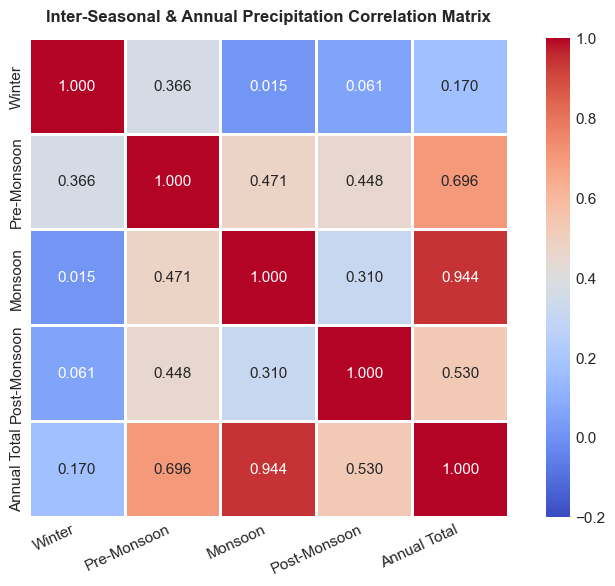

In [11]:
season_cols = ['Jan-Feb_SOURCE', 'Mar-May_SOURCE', 'Jun-Sep_SOURCE', 'Oct-Dec_SOURCE', 'ANNUAL_SOURCE']
season_labels = ['Winter', 'Pre-Monsoon', 'Monsoon', 'Post-Monsoon', 'Annual Total']

corr_df = df_wide[season_cols].dropna().copy()
corr_df.columns = season_labels
corr_matrix = corr_df.corr(method='pearson')

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-0.2, vmax=1.0, square=True, linewidths=0.8, linecolor='white')
plt.title('Inter-Seasonal & Annual Precipitation Correlation Matrix', fontsize=12, weight='bold', pad=12)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()


## 11. Synthesis & Recommendations for Stage 3

### Key Empirical Findings:
1. **National Stability vs. Regional Heterogeneity:** All-India historical annual rainfall is stationary over 1901–2015 ($p = 0.5126$, linear slope $-0.214$ mm/yr is non-significant), but local subdivisions exhibit substantial variability.
2. **Monsoon Dominance:** 75.5% of national precipitation falls during the Southwest Monsoon (`Jun-Sep`).
3. **Inverse Variability Law:** Arid zones (West Rajasthan $CV=38.4\%$, Saurashtra & Kutch $CV=36.4\%$) experience the highest relative volatility and greatest drought risk.
4. **Seasonal Independence:** Pre-monsoon and Winter rainfall show negligible correlation with the Southwest Monsoon, demonstrating that early-season precipitation cannot serve as a naive linear predictor for monsoon strength.

### Recommendations for Stage 3 (Anomaly & Change-Point Detection):
- Use subdivision-specific baseline reference periods (e.g. 1971–2000 IMD normals).
- Compute standardized anomaly indices (Z-score, SPI) so that deviations across arid and high-rainfall regimes are comparable.
- Apply non-parametric change-point algorithms (such as Pettitt's test and CUSUM) on annual series to detect historical mean shifts.
